In [16]:
# Import necessary packages
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [17]:
# Read in the MISHAPS file using Pandas
contents = pd.read_csv('MISHAPS_F1_N10.cmd', header = None, sep = '\\s+')
print(contents)

                             0           1          2      3            4   \
0       MISHAPS_F1_N10_01000001  276.789142 -28.612428   99.0  1928.808590   
1       MISHAPS_F1_N10_01000003  276.789155 -28.613827  114.0  1947.922730   
2       MISHAPS_F1_N10_01000007  276.789271 -28.598589  130.0  1739.690060   
3       MISHAPS_F1_N10_01000008  276.789271 -28.591192   90.0  1638.600590   
4       MISHAPS_F1_N10_01000010  276.789292 -28.588502   91.0  1601.849240   
5       MISHAPS_F1_N10_01000011  276.789302 -28.614594  228.0  1958.397460   
6       MISHAPS_F1_N10_01000012  276.789302 -28.594830  132.0  1688.308720   
7       MISHAPS_F1_N10_01000013  276.789303 -28.600965  165.0  1772.156130   
8       MISHAPS_F1_N10_01000014  276.789349 -28.581693   97.0  1508.795900   
9       MISHAPS_F1_N10_01000016  276.789365 -28.592672  171.0  1658.821170   
10      MISHAPS_F1_N10_01000017  276.789368 -28.585835  139.0  1565.394780   
11      MISHAPS_F1_N10_01000019  276.789378 -28.590605  168.0  1

In [18]:
# Create header titles for every column in the file
cmd_labels = ['cmdID', 'RA_z', 'Dec_z', 'ID_z', 'X_z', 'Y_z', 'z', 'z_err', 
              'sky_z', 'qflag_z', 'z?1', 'z?2', 
              'RA_r', 'Dec_r', 'ID_r', 'X_r', 'Y_r', 'r', 'r_err', 
              'sky_r', 'qflag_r', 'r?1', 'r?2']
# Important col. names --> qflag_z, qflag_r

In [19]:
# Apply those header titles to the file
contents.columns = cmd_labels
print(contents)

                          cmdID        RA_z      Dec_z   ID_z          X_z  \
0       MISHAPS_F1_N10_01000001  276.789142 -28.612428   99.0  1928.808590   
1       MISHAPS_F1_N10_01000003  276.789155 -28.613827  114.0  1947.922730   
2       MISHAPS_F1_N10_01000007  276.789271 -28.598589  130.0  1739.690060   
3       MISHAPS_F1_N10_01000008  276.789271 -28.591192   90.0  1638.600590   
4       MISHAPS_F1_N10_01000010  276.789292 -28.588502   91.0  1601.849240   
5       MISHAPS_F1_N10_01000011  276.789302 -28.614594  228.0  1958.397460   
6       MISHAPS_F1_N10_01000012  276.789302 -28.594830  132.0  1688.308720   
7       MISHAPS_F1_N10_01000013  276.789303 -28.600965  165.0  1772.156130   
8       MISHAPS_F1_N10_01000014  276.789349 -28.581693   97.0  1508.795900   
9       MISHAPS_F1_N10_01000016  276.789365 -28.592672  171.0  1658.821170   
10      MISHAPS_F1_N10_01000017  276.789368 -28.585835  139.0  1565.394780   
11      MISHAPS_F1_N10_01000019  276.789378 -28.590605  168.0  1

In [20]:
# Print out contents to see the initial before we filter out the bad quality image for the z and r-band.
print(contents.shape)
# Filter
contents = contents[(contents.loc[:,'qflag_z']==1) & (contents.loc[:,'qflag_r']==1)]
# Print out contents to see what's changed
print(contents.shape)

(127748, 23)
(44243, 23)


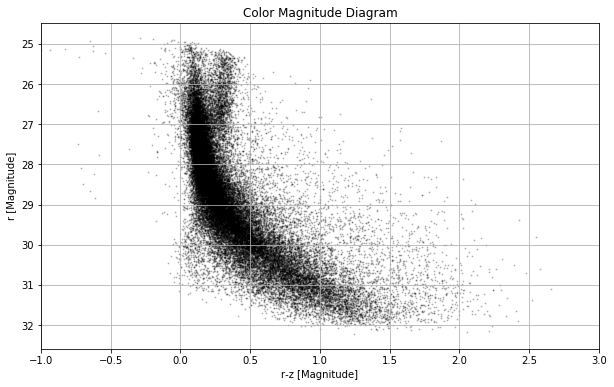

In [21]:
# Create a color magnitude diagram (CMD)
# x-axis r-z
# y-axis r

rmz = contents.loc[:, 'r'] - contents.loc[:, 'z']
r = contents.loc[:, 'r']

plt.figure(figsize = (10,6))
plt.tight_layout()

plt.scatter(rmz, r, s=1, color = 'k', alpha = 0.2)

plt.gca().invert_yaxis() # Flips the y-axis --> normal for cmds
plt.xlim(-1, 3)

plt.title('Color Magnitude Diagram')
plt.xlabel('r-z [Magnitude]')
plt.ylabel('r [Magnitude]')
plt.grid(True)

plt.show()


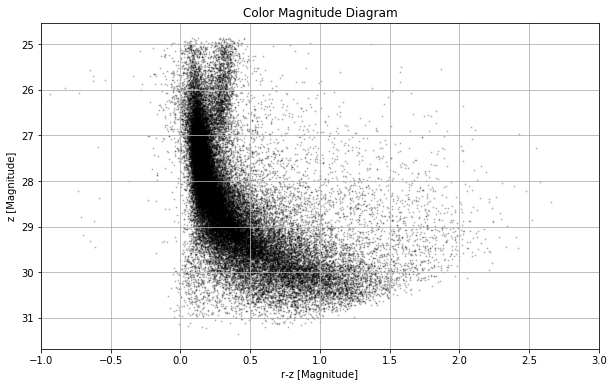

In [22]:
# Create a color magnitude diagram (CMD)
# x-axis r-z
# y-axis z

rmz = contents.loc[:, 'r'] - contents.loc[:, 'z']
z = contents.loc[:, 'z']

plt.figure(figsize = (10,6))
plt.tight_layout()

plt.scatter(rmz, z, s=1, color = 'k', alpha = 0.2)

plt.gca().invert_yaxis() # Flips the y-axis --> normal for cmds
plt.xlim(-1, 3)

plt.title('Color Magnitude Diagram')
plt.xlabel('r-z [Magnitude]')
plt.ylabel('z [Magnitude]')
plt.grid(True)

plt.show()

/usr/local/anaconda-python3.7-conda4.5/lib/python3.7/site-packages/scipy/stats/_binned_statistic.py:607: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  result = result[core]


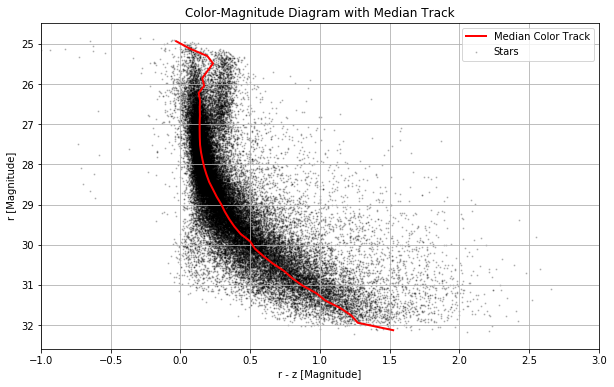

In [7]:
from scipy.stats import binned_statistic # calculates statistics (like mean, median, std) over bins of a given data range

# Bin CMD by magnitude
bins = 40 # divide the magnitude range into 40 equal-width intervals
bin_edges = np.linspace(r.min(), r.max(), bins + 1) # creates an array of evenly spaced values from r.min() to r.max(), with bins + 1 points
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1]) # takes the average of the lower and upper edge of each bin

med_color, _, _ = binned_statistic(r, rmz, statistic='median', bins=bin_edges) # calculates the median color (r - z, stored in rmz) within each bin of magnitude r
# the underscores are unused outputs: one is the bin number for each input point, and one is the bin edges

# Plot CMD and trend
plt.figure(figsize=(10, 6))
plt.tight_layout()

plt.scatter(rmz, r, s=1, alpha=0.2, color='black', label='Stars')
plt.plot(med_color, bin_centers, color='red', lw=2, label='Median Color Track')

plt.gca().invert_yaxis()
plt.xlim(-1, 3)

plt.xlabel('r - z [Magnitude]')
plt.ylabel('r [Magnitude]')
plt.title('Color-Magnitude Diagram with Median Track')
plt.legend()
plt.grid(True)

plt.show()

/usr/local/anaconda-python3.7-conda4.5/lib/python3.7/site-packages/scipy/stats/_binned_statistic.py:607: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  result = result[core]


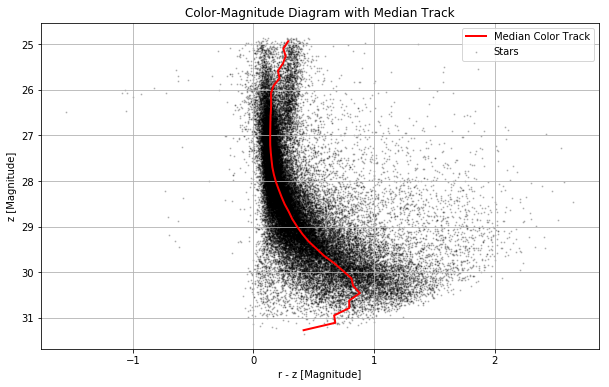

In [9]:
# Bin CMD by magnitude
num_bins = 40
bin_edgez = np.linspace(z.min(), z.max(), num_bins + 1)
bin_centerz = 0.5 * (bin_edgez[1:] + bin_edgez[:-1])

med_colorz, _, _ = binned_statistic(z, rmz, statistic='median', bins=bin_edgez)

# Plot CMD and trend
plt.figure(figsize=(10, 6))
plt.tight_layout()

plt.scatter(rmz, z, s=1, alpha=0.2, color='black', label='Stars')
plt.plot(med_colorz, bin_centerz, color='red', lw=2, label='Median Color Track')

plt.gca().invert_yaxis()
plt.xlabel('r - z [Magnitude]')
plt.ylabel('z [Magnitude]')
plt.title('Color-Magnitude Diagram with Median Track')
plt.legend()
plt.grid(True)

plt.show()

In [10]:
# Apply error cut: remove stars with large magnitude uncertainties
filtered = contents[(contents['r_err'] < 0.1) & (contents['z_err'] < 0.1)]

color = filtered['r'] - filtered['z']
mag = filtered['r']

# Bin definitions
num_bins = 40
bin_edges = np.linspace(mag.min(), mag.max(), num_bins + 1)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# Median and std of color in bins
med_color, _, _ = binned_statistic(mag, color, statistic='median', bins=bin_edges)
std_color, _, _ = binned_statistic(mag, color, statistic='std', bins=bin_edges)

# Assign bin index for each star
bin_idx = np.digitize(mag, bins=bin_edges) - 1

# Preallocate outlier mask
outlier_mask = np.zeros_like(color, dtype=bool)

# Valid indices within bin range
valid_indices = np.where((bin_idx >= 0) & (bin_idx < num_bins))[0]

# Apply 2-sigma condition safely
for i in valid_indices:
    idx = bin_idx[i]
    if np.abs(color[i] - med_color[idx]) > 2 * std_color[idx]:
        outlier_mask[i] = True

# Outliers
outliers = filtered[outlier_mask]

# Get the outlier stars
outliers = filtered[outlier_mask]

# Plot
plt.figure(figsize=(8, 6))
plt.scatter(color, mag, s=1, alpha=0.1, color='gray', label='All Stars')
plt.scatter(outliers['r'] - outliers['z'], outliers['r'], s=5, color='orange', label='>2σ Outliers')
plt.plot(med_color, bin_centers, 'r-', label='Median Color Track')

plt.gca().invert_yaxis()
plt.xlabel('r - z [Color]')
plt.ylabel('r [Magnitude]')
plt.title('CMD with Highlighted Outliers')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

/usr/local/anaconda-python3.7-conda4.5/lib/python3.7/site-packages/scipy/stats/_binned_statistic.py:607: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  result = result[core]


KeyError: 0

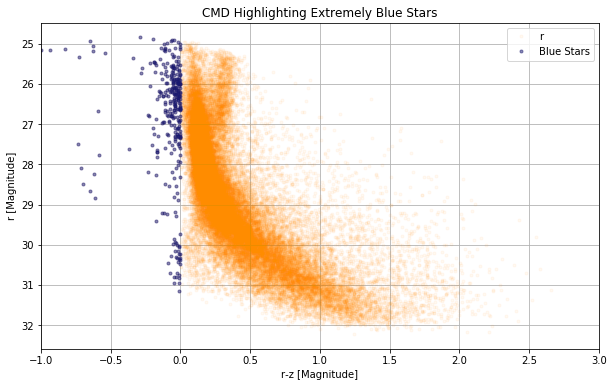

In [11]:
# Highlight extremely blue stars (r - z < 0)
blue_stars = contents[rmz < 0]

plt.figure(figsize = (10,6))
plt.tight_layout()

plt.plot(rmz, r, '.', color='darkorange', alpha= 0.05) # Replot main cloud
plt.plot(blue_stars['r'] - blue_stars['z'], blue_stars['r'], '.', color='midnightblue', alpha= 0.5, label='Blue Stars') # Plot blue stars

plt.gca().invert_yaxis()
plt.xlim(-1, 3)

plt.title('CMD Highlighting Extremely Blue Stars')
plt.xlabel('r-z [Magnitude]')
plt.ylabel('r [Magnitude]')
plt.legend(loc = 'best')
plt.grid(True)
plt.show()

In [1]:
# Plot relative to the rest of the galaxy
# Plot the error on the photometry (r-err, z-err columns) as a function of the magnitude columns, ex: x= r, y=r-err

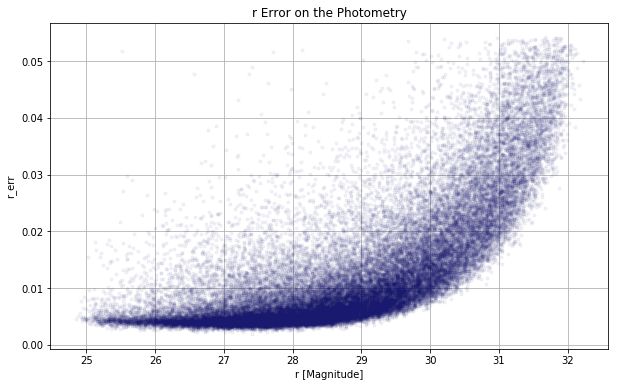

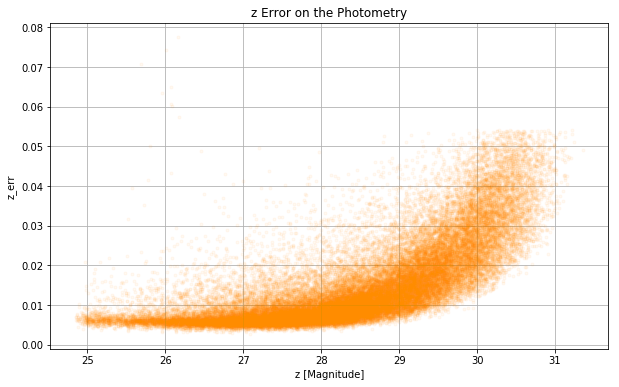

In [12]:
r_err = contents.loc[:, 'r_err']
z_err = contents.loc[:, 'z_err']
z = contents.loc[:, 'z']

plt.figure(figsize = (10,6))
plt.tight_layout()

plt.plot(r, r_err,  '.', color = 'midnightblue', alpha = 0.05)


plt.title('r Error on the Photometry')
plt.xlabel('r [Magnitude]')
plt.ylabel('r_err')
plt.grid(True)
plt.show()

plt.figure(figsize = (10,6))
plt.tight_layout()

plt.plot(z, z_err, '.', color = 'darkorange', alpha = 0.05)


plt.title('z Error on the Photometry')
plt.xlabel('z [Magnitude]')
plt.ylabel('z_err')
plt.grid(True)
plt.show()

In [15]:
mag_array = np.array(r)
dispersion = np.std(mag_array)
print(f"Magnitude Dispersion: {dispersion:.2f}")

Magnitude Dispersion: 1.50


In [ ]:
r_hist, r_bins = np.histogram(r, bins=50)
r_bin_centers = 0.5 * (r_bins[1:] + r_bins[:-1])
r_peak = r_bin_centers[np.argmax(r_hist)]

rmz_hist, rmz_bins = np.histogram(rmz, bins=50)
rmz_bin_centers = 0.5 * (rmz_bins[1:] + rmz_bins[:-1])
rmz_peak = rmz_bin_centers[np.argmax(rmz_hist)]

popt_r, _ = curve_fit(gauss, r_bin_centers, r_hist, p0=[r_hist.max(), r_peak, 0.3])
r_peak = popt_r[1]

popt_rmz, _ = curve_fit(gauss, rmz_bin_centers, rmz_hist, p0=[rmz_hist.max(), r_z_peak, 0.2])
rmz_peak = popt_rmz[1]

M_r = 0.6  # Absolute magnitude of red clump stars in r-band
rmz_intrinsic = 0.55  # Intrinsic r-z color
E_rmz = r_z_peak - r_z_intrinsic
R_r = 2.3  # Extinction coefficient for SDSS r-band
A_r = R_r * E_rz
mu = r_peak - M_r - A_r  # Distance modulus
d_pc = 10 ** ((mu + 5) / 5)  # Convert to parsecs

print(f"Clump peak magnitude (r): {r_peak:.2f}")
print(f"Clump peak color (r-z): {r_z_peak:.2f}")
print(f"Color excess E(r-z): {E_rz:.2f}")
print(f"Extinction A_r: {A_r:.2f}")
print(f"Distance modulus: {mu:.2f}")
print(f"Distance: {d_pc/1000:.2f} kpc")